In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec
import matplotlib.colors as colors


import os
import scanpy as sc

import seaborn as sns
import snapatac2 as snap

snap.__version__



plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6

/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load fragments into snap-atac and droplet-level QCs  

In [2]:
blacklist_file = '/home/syyang/GitRepo/SADE/ref/hg38/hg38-blacklist.bed'

In [3]:
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
Union_cell_subdir = os.path.join(entropy_dir, '_cell_calling_comparison')
Union_cell_all_info_file = os.path.join(Union_cell_subdir, 'Union_cell_3set_w_RNAQC.tsv')
union_cell_all_info = pd.read_csv(Union_cell_all_info_file, sep='\t', index_col=0)
union_cell_info = union_cell_all_info[union_cell_all_info['_3set_identified_by_atac'] != 'none']
union_cell_info['index'] = union_cell_info.index

union_cell_info.head(2)

/tmp/ipykernel_4180129/275559256.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  union_cell_info['index'] = union_cell_info.index


,total_fragments,atac_pass_CR,atac_pass_entropy,atac_pass_archr_TSS,_2set_identified_by_atac_SC,_2set_identified_by_atac_ST,_3set_identified_by_atac,Entropy,DNA_debris,P_closed_state,atac_barcodes.1,rna_bc,rna_pass_CR,index
atac_barcodes,,,,,,,,,,,,,,
AAACAAGCAAGTTAGT-1,2412,True,True,True,both,both,common,0.218328,NO,0.965116,AAACAAGCAAGTTAGT,GGCTAGTGTGTTAGCA,True,AAACAAGCAAGTTAGT-1
AAACAAGCATTTCTTC-1,9030,True,True,True,both,both,common,0.074451,NO,0.990949,AAACAAGCATTTCTTC,GGCTAGTGTACGTTTC,True,AAACAAGCATTTCTTC-1


In [7]:
# SADE only flag cellular-debris among the droplets passed entropy, meaning the one missing such flag is not cellular-debris.
print(union_cell_info.groupby('DNA_debris', dropna=False).size())
union_cell_info['DNA_debris'] = union_cell_info['DNA_debris'].fillna('NO')

DNA_debris
NO     2340
YES      22
NaN      22
dtype: int64


/tmp/ipykernel_4180129/1521311556.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  union_cell_info['DNA_debris'] = union_cell_info['DNA_debris'].fillna('NO')


In [8]:
amulet_doublet_atac_file = os.path.join(Union_cell_subdir, 'AMULET_output/MultipletBarcodes_01.txt')
doublet_atac_barcodes = pd.read_csv(amulet_doublet_atac_file, header=None)
doublet_atac_barcodes.columns = ['barcodes']
doublet_atac_barcodes['atac_bc'] = doublet_atac_barcodes['barcodes']
doublet_atac_barcodes.head(2)

,barcodes,atac_bc
0,AAAGCCTAGGATTATG-1,AAAGCCTAGGATTATG-1
1,AAAGGCGCACTAATCC-1,AAAGGCGCACTAATCC-1


In [9]:
fragment_file = os.path.join(entropy_dir, '_cell_calling_comparison', 'union_bc_fragments.tsv.gz')

data = snap.pp.import_fragments(
    fragment_file,
    chrom_sizes=snap.genome.hg38,
    sorted_by_barcode=False,
)
data

AnnData object with n_obs × n_vars = 2384 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito'
    uns: 'reference_sequences'
    obsm: 'fragment_paired'

In [10]:
col_list = ['rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 
            'DNA_debris']
for col in col_list:
    data.obs[col] = data.obs.index.map(union_cell_info.set_index('index')[col])

data.obs['amulet_doublet_atac'] = data.obs.index.isin(doublet_atac_barcodes['atac_bc'])


In [11]:
union_cell_info['DNA_debris'].value_counts()

DNA_debris
NO     2362
YES      22
Name: count, dtype: int64

In [12]:
data.obs.groupby([ '_3set_identified_by_atac',  'amulet_doublet_atac']).size().unstack(fill_value=0)

amulet_doublet_atac,False,True
_3set_identified_by_atac,,
CR unique,41,20
"CR+TSS, not SADE",33,0
SADE unique,118,0
"SADE+CR, not TSS",62,11
"SADE+TSS, not CR",118,0
TSS unique,189,0
common,1727,65


In [13]:
data

AnnData object with n_obs × n_vars = 2384 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac'
    uns: 'reference_sequences'
    obsm: 'fragment_paired'

In [ ]:
snap.metrics.tsse(data, snap.genome.hg38)  # Calculate TSSe with snap-atac


# Use all cells in the union set -- (not filtering out DNA-debris or amulet estimated doublets)
## Cluster and dimention reduction

In [15]:
snap.pp.add_tile_matrix(data)

snap.pp.select_features(data, blacklist=blacklist_file)

snap.tl.spectral(data) # low rank approximation

snap.pp.knn(data) # build similarity graph

snap.tl.leiden(data, resolution=1.5) # cluster cells

snap.tl.umap(data) # umap visualization embedding

2026-09-18 08:47:57 - INFO - Selected 496371 features.
/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


In [16]:
data

AnnData object with n_obs × n_vars = 2384 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'spectral_eigenvalue'
    obsm: 'fragment_paired', 'X_spectral', 'X_umap'
    obsp: 'distances'

In [22]:
#sc.pl.umap(data, color='leiden',s = 10)

In [18]:
data.obs.groupby(['_3set_identified_by_atac', 'leiden'] ).size().unstack(fill_value=0)

/tmp/ipykernel_4180129/3495514684.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.obs.groupby(['_3set_identified_by_atac', 'leiden'] ).size().unstack(fill_value=0)


leiden,0,1,2,3,4,5,6,7,8,9,10,11
_3set_identified_by_atac,,,,,,,,,,,,
CR unique,29,0,7,5,1,13,0,6,0,0,0,0
"CR+TSS, not SADE",4,0,4,7,0,7,0,11,0,0,0,0
SADE unique,63,0,11,4,2,16,0,22,0,0,0,0
"SADE+CR, not TSS",21,0,11,6,5,11,0,18,0,1,0,0
"SADE+TSS, not CR",7,2,17,16,15,36,4,16,3,1,1,0
TSS unique,189,0,0,0,0,0,0,0,0,0,0,0
common,12,307,210,193,191,125,176,76,143,141,133,85


Text(0.5, 0.98, 'ATAC-union-bc-UMAP')

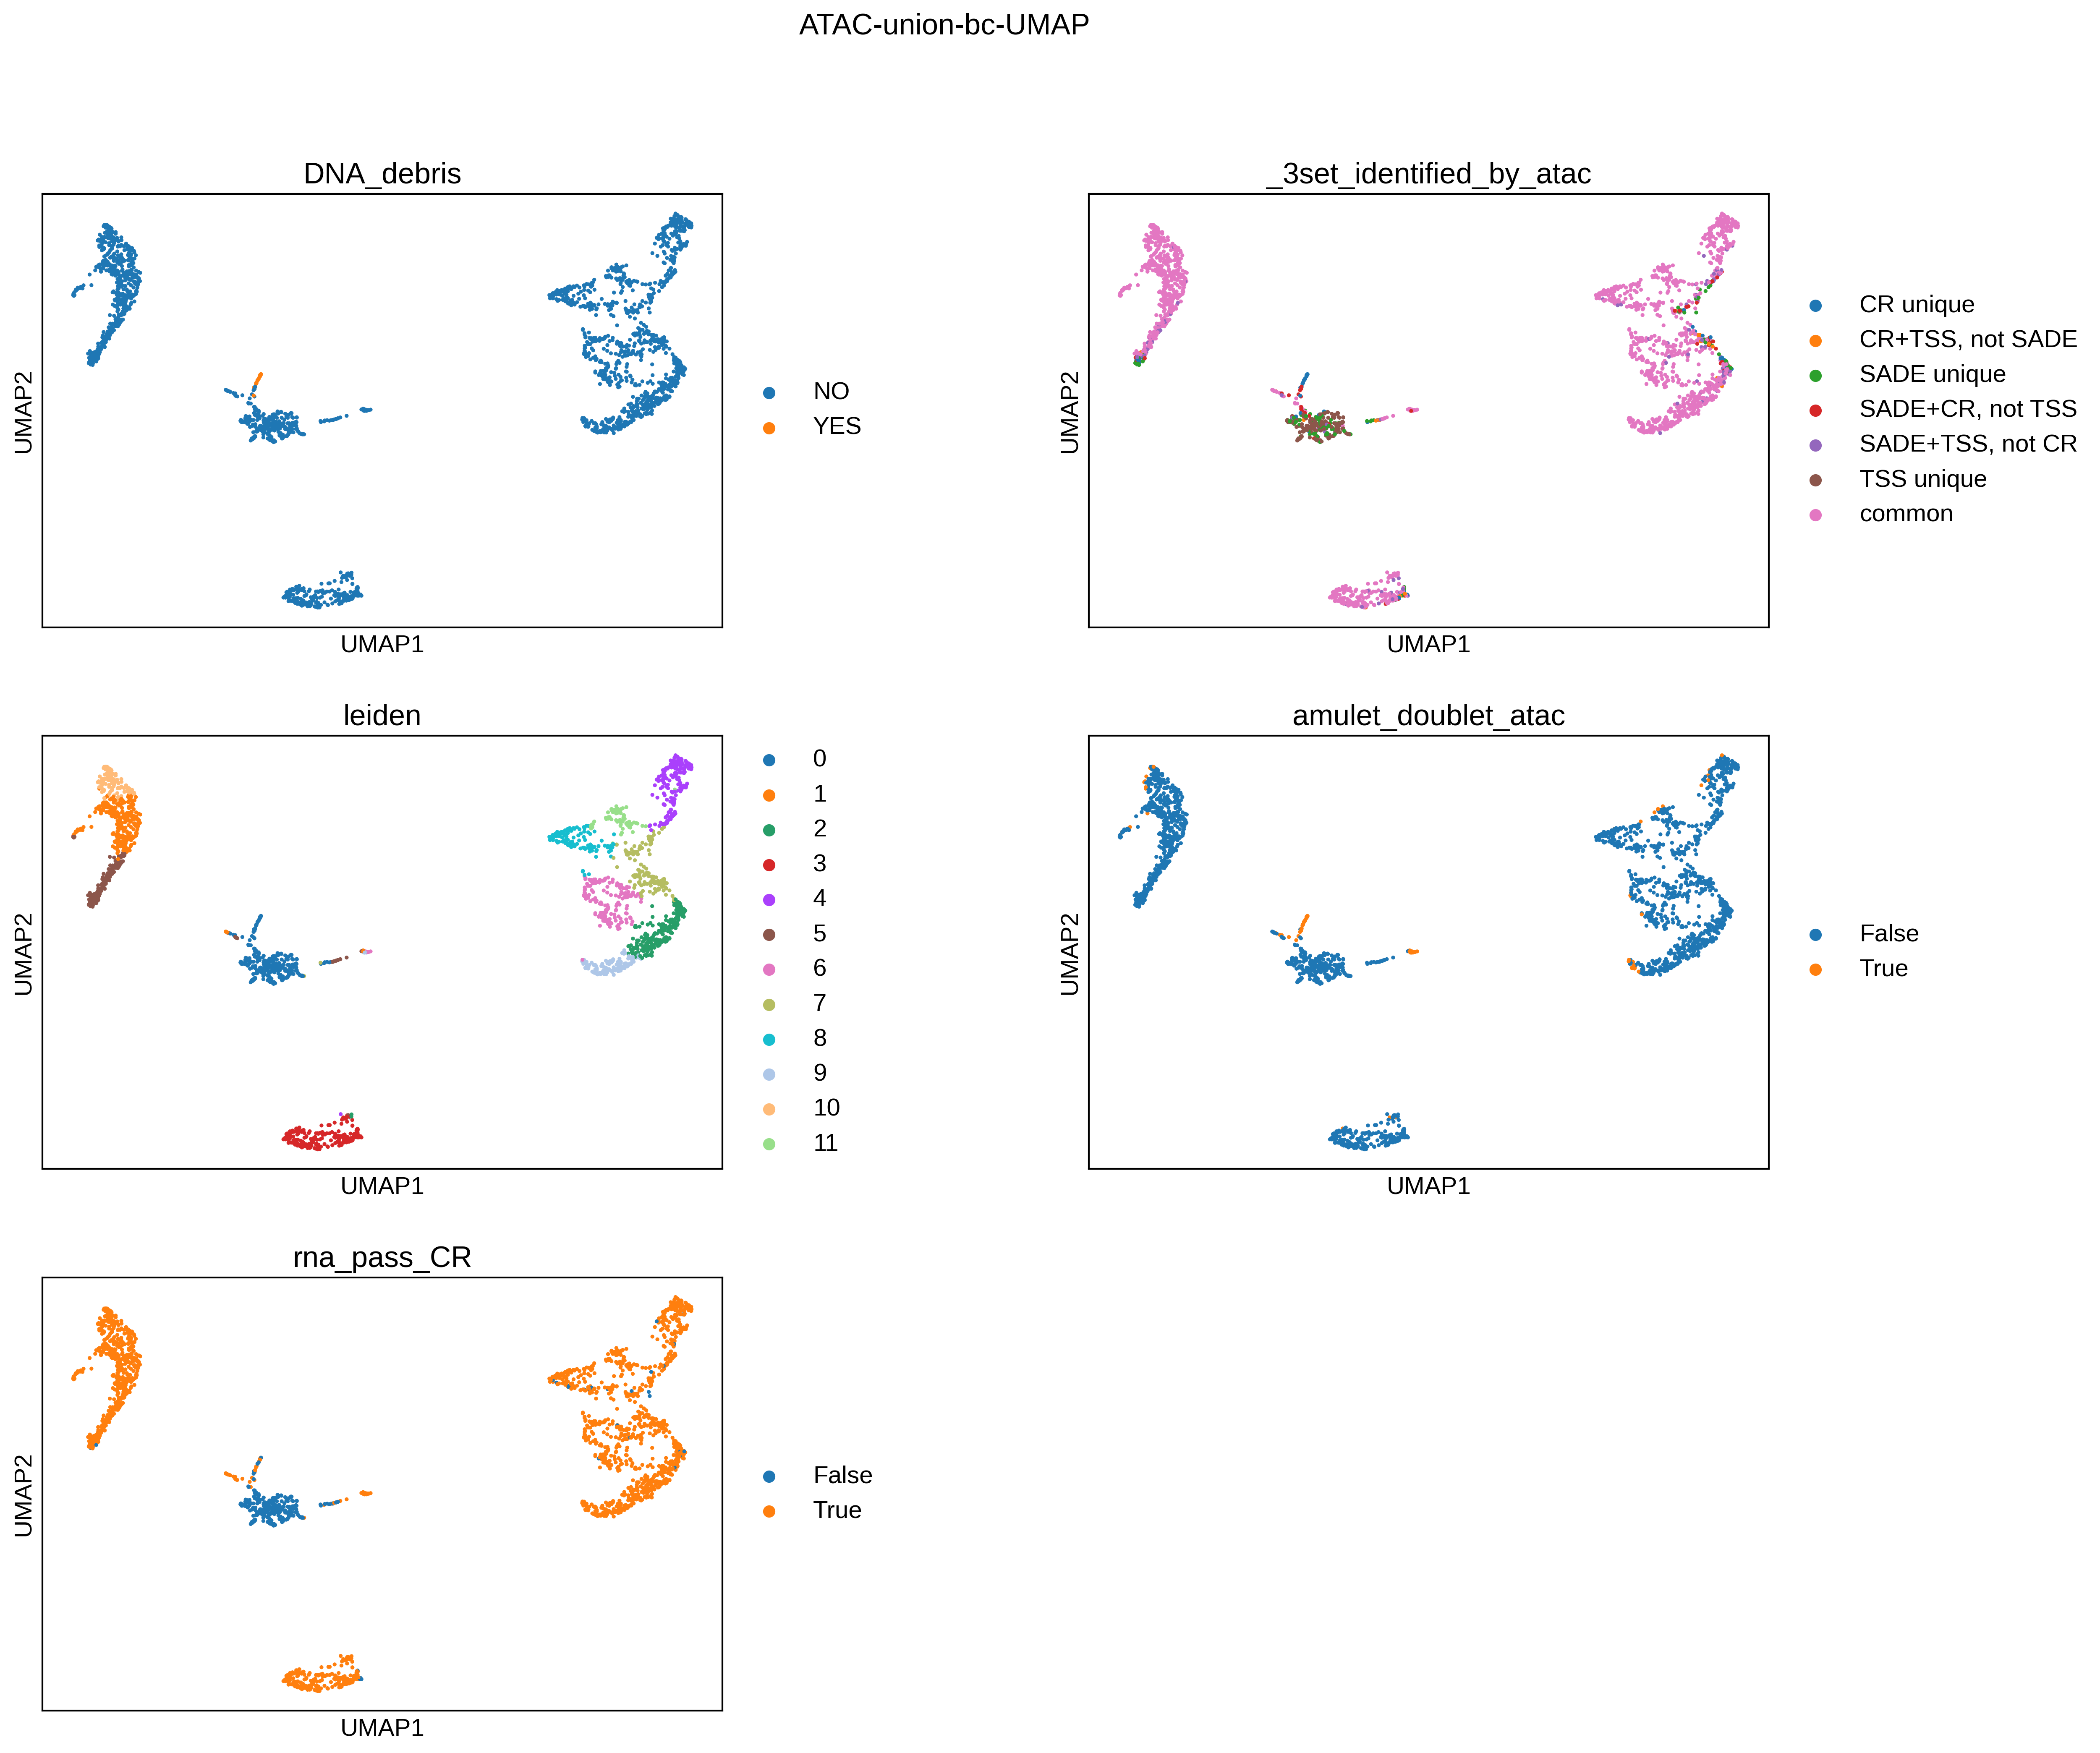

In [38]:
fig = sc.pl.umap(data, color=['DNA_debris', '_3set_identified_by_atac', 'leiden', 'amulet_doublet_atac', 'rna_pass_CR'], s=20, ncols=2, wspace=0.4,
                  return_fig=True, show=False)
fig.suptitle('ATAC-union-bc-UMAP')


In [ ]:
# Save results 
if not os.path.exists(os.path.join(Union_cell_subdir, '_SNAPataC_analysis')):
    os.makedirs(os.path.join(Union_cell_subdir, '_SNAPataC_analysis'))
data.write_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_all_unioncells.h5ad'))

# Use cells in the union set after filtering out DNA-debris or amulet estimated doublets 
## Cluster and dimention reduction

In [23]:
data

AnnData object with n_obs × n_vars = 2384 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'spectral_eigenvalue', 'leiden_colors', 'DNA_debris_colors', '_3set_identified_by_atac_colors', 'amulet_doublet_atac_colors', 'rna_pass_CR_colors'
    obsm: 'fragment_paired', 'X_spectral', 'X_umap'
    obsp: 'distances'

In [24]:
data_filter = data[ (data.obs['amulet_doublet_atac'] == False) & (data.obs['DNA_debris'] == 'NO') ].copy()

In [27]:
data.obs.groupby(['amulet_doublet_atac', 'DNA_debris'] ).size().unstack(fill_value=0)

/tmp/ipykernel_4180129/2269663657.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.obs.groupby(['amulet_doublet_atac', 'DNA_debris'] ).size().unstack(fill_value=0)


DNA_debris,NO,YES
amulet_doublet_atac,,
False,2286,2
True,76,20


In [28]:
data_filter

AnnData object with n_obs × n_vars = 2286 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'rna_pass_CR', 'atac_pass_CR', 'atac_pass_entropy', 'atac_pass_archr_TSS', '_2set_identified_by_atac_SC', '_2set_identified_by_atac_ST', '_3set_identified_by_atac', 'DNA_debris', 'amulet_doublet_atac', 'tsse', 'leiden'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile', 'spectral_eigenvalue', 'leiden_colors', 'DNA_debris_colors', '_3set_identified_by_atac_colors', 'amulet_doublet_atac_colors', 'rna_pass_CR_colors'
    obsm: 'fragment_paired', 'X_spectral', 'X_umap'
    obsp: 'distances'

In [30]:
snap.pp.select_features(data_filter, blacklist=blacklist_file)

a = snap.tl.spectral(data_filter, inplace=False)
 
data_filter.obsm['filtered_X_spectral'] = a[1]
data_filter.uns['filtered_spectral_eigenvalue'] = a[0]

data_filter.obsp['filtered_distance'] = snap.pp.knn(data_filter, use_rep='filtered_X_spectral', inplace=False)

data_filter.uns['filtered_distance'] ='filtered_distance'  # point to the name in obsp 

data_filter.obsm['filtered_X_umap'] = snap.tl.umap(data_filter,  use_rep='filtered_X_spectral',inplace=False)

data_filter.obs['filtered_leiden'] = snap.tl.leiden(data_filter.obsp['filtered_distance'], 
             resolution=1.5) # cluster cells

2026-09-18 08:57:15 - INFO - Selected 497281 features.
/home/syyang/python_virtuenv/atac_tobias3.13/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Text(0.5, 0.98, 'ATAC-union-bc-UMAP')

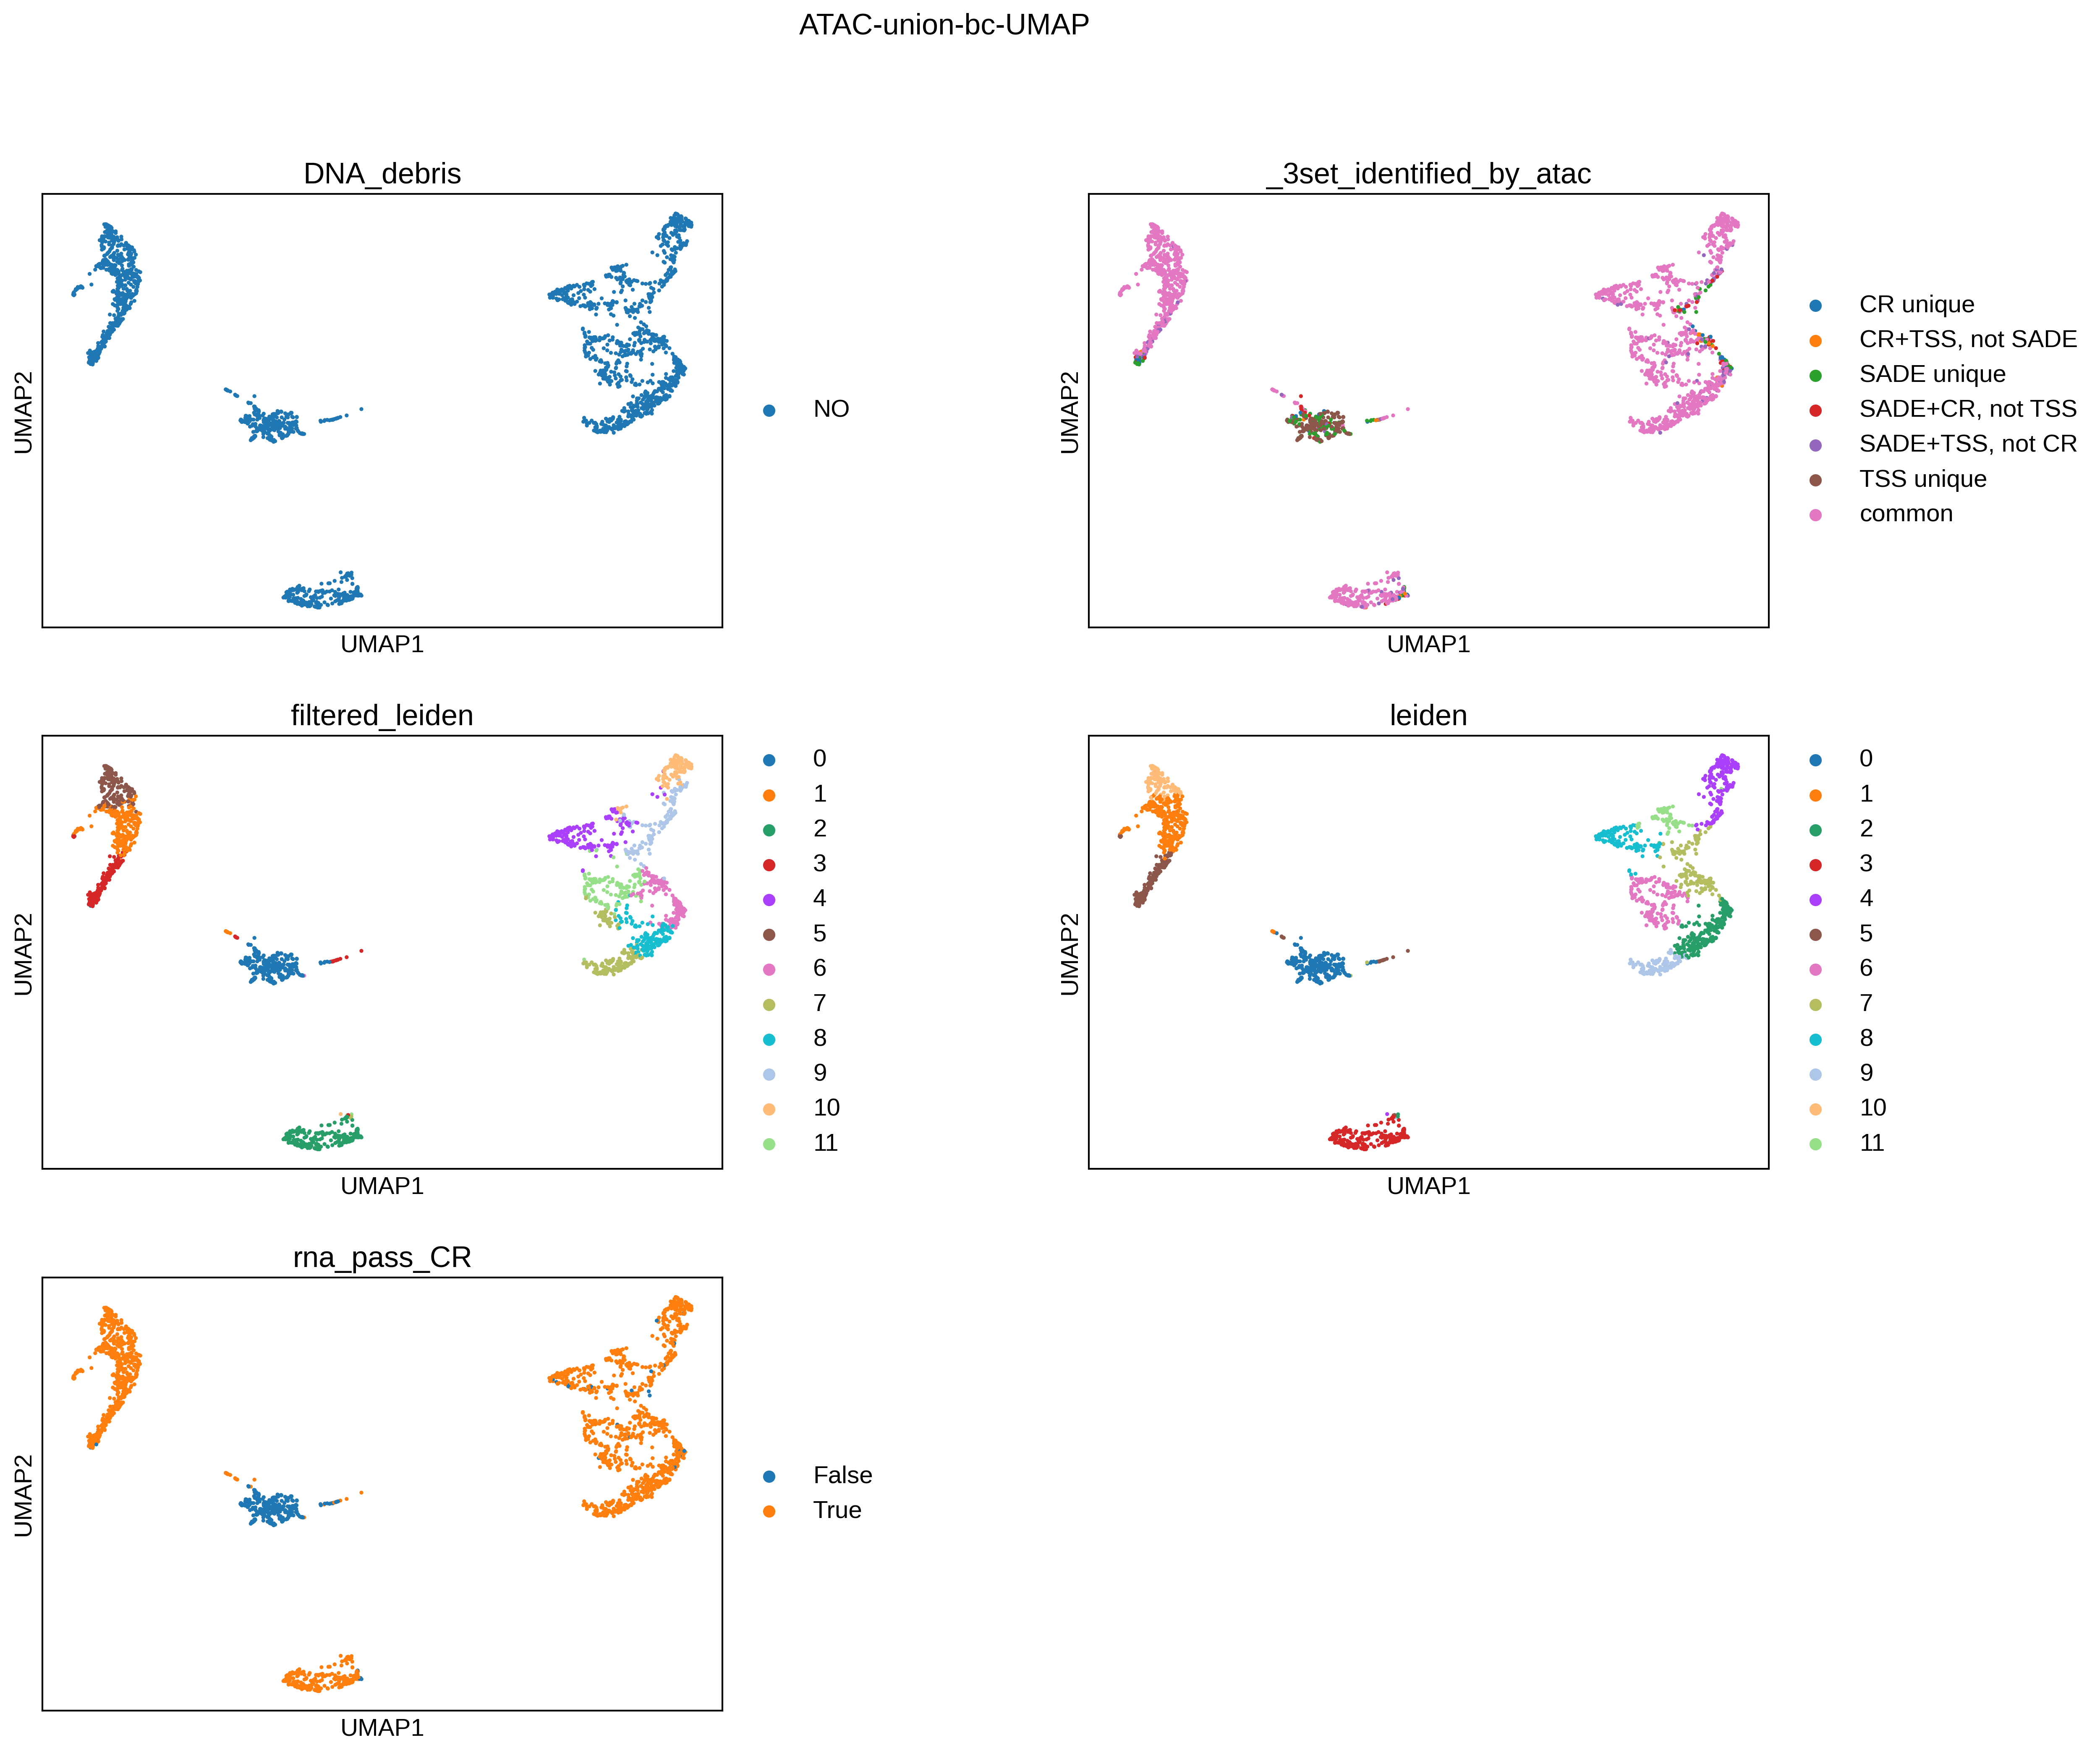

In [39]:
fig = sc.pl.umap(data_filter, color=['DNA_debris', '_3set_identified_by_atac', 'filtered_leiden', 'leiden', 'rna_pass_CR'], s=20, ncols=2, wspace=0.4,
                    return_fig=True, show=False)
fig.suptitle('ATAC-union-bc-UMAP')

Text(0.5, 0.98, 'ATAC-union-noDebrisDoublet-bc-UMAP')

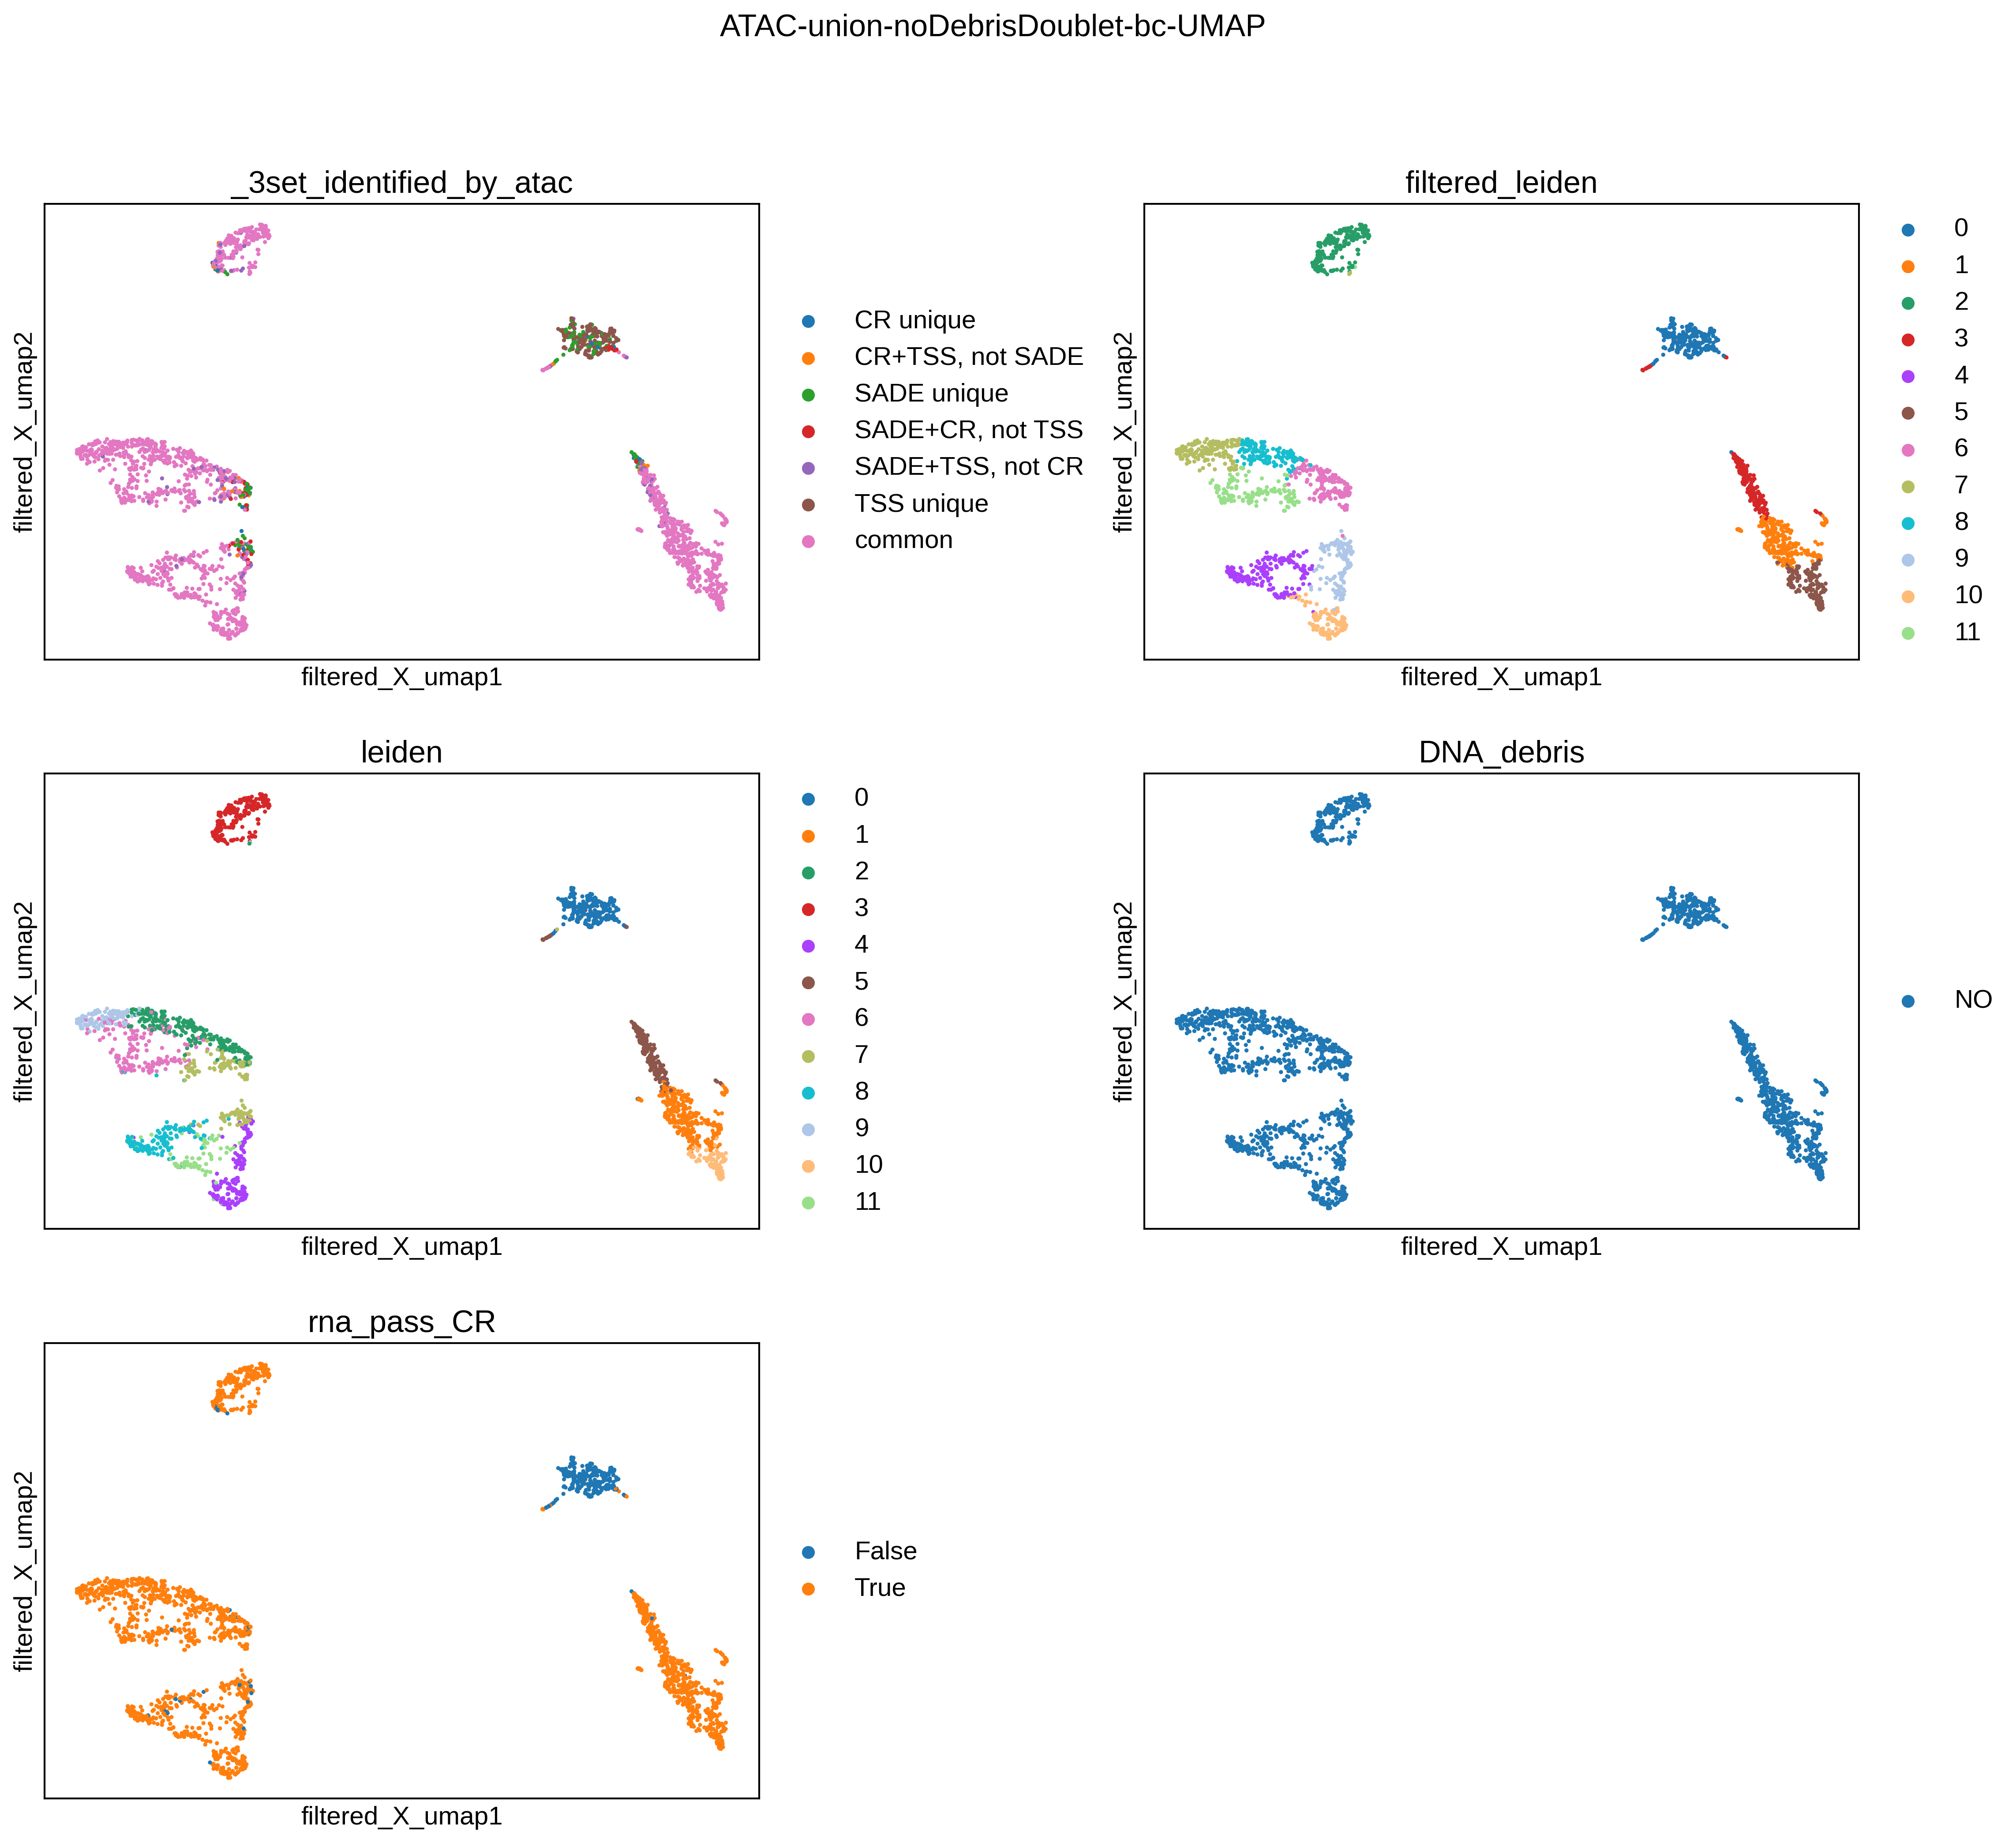

In [40]:
fig = sc.pl.embedding(data_filter,basis='filtered_X_umap', color=[ '_3set_identified_by_atac', 'filtered_leiden', 'leiden', 'DNA_debris', 'rna_pass_CR'], s=20, ncols=2, wspace=0.4,
                    return_fig=True, show=False)
fig.suptitle('ATAC-union-noDebrisDoublet-bc-UMAP')

In [33]:
data_filter.obs.groupby(['leiden', 'filtered_leiden'] ).size().unstack(fill_value=0)

/tmp/ipykernel_4180129/1483797836.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data_filter.obs.groupby(['leiden', 'filtered_leiden'] ).size().unstack(fill_value=0)


filtered_leiden,0,1,2,3,4,5,6,7,8,9,10,11
leiden,,,,,,,,,,,,
0,289,1,0,1,0,0,0,0,0,0,0,0
1,0,234,0,2,0,62,0,0,0,0,0,0
2,0,0,0,0,0,0,105,16,138,0,0,1
3,1,0,225,0,0,0,0,0,0,0,0,2
4,0,0,0,0,5,0,0,0,0,81,123,0
5,1,5,0,202,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,5,39,19,0,0,104
7,1,0,0,0,3,0,68,0,0,53,0,24
8,0,0,0,0,139,0,0,0,0,1,0,4


In [ ]:
# Save results
data_filter.write_h5ad(os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'binnedGenome_unioncells_noDebrisDoublets.h5ad'))

data_filter.obs['filtered_leiden'].to_csv(
    os.path.join(Union_cell_subdir, '_SNAPataC_analysis', 'snap_cluster_unioncells_noDebrisDoublets.tsv'), index=True,
                                          sep='\t', header=True)